In [1]:

# ==================================================
# PHAN 0 - KHOI TAO MOI TRUONG VA DU LIEU
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from urllib.parse import unquote

# Cau hinh chung cua nhom
RANDOM_STATE = 42

# File Excel goc cua thay tren GitHub
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "Minhhieu3012/wifi-localization-data-mining/"
    "part1-eda-preprocessing/"
    "data/raw/D08%20-%20wifi_localization.xlsx"
)

# Kiem tra file dang doc
print("=== FILE EXCEL GOC ===")
print("Ten file:", unquote(DATA_URL.split("/")[-1]))

# Kiem tra sheet
excel = pd.ExcelFile(DATA_URL)
print("Danh sach sheet:", excel.sheet_names)

# Doc dung sheet du lieu
df_raw = pd.read_excel(
    DATA_URL,
    sheet_name="wifi_localization",
    header=None
)

# Kiem tra kich thuoc
print("Kich thuoc du lieu:", df_raw.shape)

assert df_raw.shape == (2000, 8)

print("\nKHOI TAO THANH CONG!")
display(df_raw.head())


=== FILE EXCEL GOC ===
Ten file: D08 - wifi_localization.xlsx
Danh sach sheet: ['Sheet1', 'wifi_localization']
Kich thuoc du lieu: (2000, 8)

KHOI TAO THANH CONG!


,0,1,2,3,4,5,6,7
0,-64,-56,-61,-66,-71,-82,-81,1
1,-68,-57,-61,-65,-71,-85,-85,1
2,-63,-60,-60,-67,-76,-85,-84,1
3,-61,-60,-68,-62,-77,-90,-80,1
4,-63,-65,-60,-63,-77,-81,-87,1


In [2]:

# Kiem tra kich thuoc truoc khi chuyen doi
assert df_raw.shape == (2000, 8), "Du lieu khong dung kich thuoc!"

# Dat ten cho 7 dac trung WiFi va nhan phong
columns = [f"WiFi_{i}" for i in range(1, 8)] + ["Room"]

df = df_raw.copy()
df.columns = columns

# Chuyen 7 cot WiFi sang float64
for col in columns[:7]:
    df[col] = pd.to_numeric(df[col], errors="raise").astype("float64")

# Chuyen nhan phong sang so nguyen
df["Room"] = pd.to_numeric(
    df["Room"], errors="raise"
).astype("int64")

# Luu CSV trong phien Colab
df.to_csv("wifi_localization.csv", index=False)

print("Da tao file wifi_localization.csv")
print("Kich thuoc:", df.shape)
print("\nKieu du lieu:")
print(df.dtypes)

display(df.head())


Da tao file wifi_localization.csv
Kich thuoc: (2000, 8)

Kieu du lieu:
WiFi_1    float64
WiFi_2    float64
WiFi_3    float64
WiFi_4    float64
WiFi_5    float64
WiFi_6    float64
WiFi_7    float64
Room        int64
dtype: object


,WiFi_1,WiFi_2,WiFi_3,WiFi_4,WiFi_5,WiFi_6,WiFi_7,Room
0,-64.0,-56.0,-61.0,-66.0,-71.0,-82.0,-81.0,1
1,-68.0,-57.0,-61.0,-65.0,-71.0,-85.0,-85.0,1
2,-63.0,-60.0,-60.0,-67.0,-76.0,-85.0,-84.0,1
3,-61.0,-60.0,-68.0,-62.0,-77.0,-90.0,-80.0,1
4,-63.0,-65.0,-60.0,-63.0,-77.0,-81.0,-87.0,1


In [3]:

# KIEM TRA FILE CSV SAU KHI CHUYEN DOI

# 1. Doc lai CSV
df_csv = pd.read_csv("wifi_localization.csv")

# 2. Kiem tra kich thuoc
print("Kich thuoc CSV:", df_csv.shape)

# 3. Kiem tra ten cot
print("\nDanh sach cot:")
print(df_csv.columns.tolist())

# 4. Kiem tra so luong nhan phong
print("\nSo luong mau theo phong:")
print(df_csv["Room"].value_counts().sort_index())

# 5. Kiem tra gia tri thieu
print("\nTong gia tri thieu:", df_csv.isna().sum().sum())

# 6. Doi chieu voi du lieu vua chuyen
pd.testing.assert_frame_equal(df, df_csv)

# 7. Xac nhan kich thuoc va nhan
assert df_csv.shape == (2000, 8)
assert set(df_csv["Room"].unique()) == {1, 2, 3, 4}

print("\nKIEM TRA THANH CONG!")
print("CSV khop voi du lieu Excel da chuyen doi.")


Kich thuoc CSV: (2000, 8)

Danh sach cot:
['WiFi_1', 'WiFi_2', 'WiFi_3', 'WiFi_4', 'WiFi_5', 'WiFi_6', 'WiFi_7', 'Room']

So luong mau theo phong:
Room
1    500
2    500
3    500
4    500
Name: count, dtype: int64

Tong gia tri thieu: 0

KIEM TRA THANH CONG!
CSV khop voi du lieu Excel da chuyen doi.


In [4]:

from google.colab import files

files.download("wifi_localization.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:

from google.colab import files

# Kiem tra file CSV truoc khi tai
df_check = pd.read_csv("wifi_localization.csv")

assert df_check.shape == (2000, 8)

print("CSV hop le:", df_check.shape)

# Tai CSV tu Colab ve may
files.download("wifi_localization.csv")


CSV hop le: (2000, 8)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 1. Khám phá và tiền xử lý dữ liệu (EDA)

### 1a. Kích thước và số chiều dữ liệu

Mục tiêu: Xác định số lượng mẫu, số thuộc tính,
số đặc trưng đầu vào và số lớp của bộ dữ liệu
WiFi Localization.


In [6]:

# PHAN 1A - KICH THUOC VA SO CHIEU DU LIEU

# Doc CSV da chuan bi tren GitHub
CSV_URL = (
    "https://raw.githubusercontent.com/"
    "Minhhieu3012/wifi-localization-data-mining/"
    "part1-eda-preprocessing/"
    "data/processed/wifi_localization.csv"
)

df = pd.read_csv(CSV_URL)

so_mau, so_cot = df.shape
so_dac_trung = so_cot - 1
so_lop = df["Room"].nunique()

print("=== THONG TIN BO DU LIEU ===")
print("So luong mau:", so_mau)
print("Tong so cot:", so_cot)
print("So dac trung dau vao:", so_dac_trung)
print("So lop phong:", so_lop)

print("\n=== 5 DONG DU LIEU DAU TIEN ===")
display(df.head())

assert df.shape == (2000, 8)
assert so_lop == 4


=== THONG TIN BO DU LIEU ===
So luong mau: 2000
Tong so cot: 8
So dac trung dau vao: 7
So lop phong: 4

=== 5 DONG DU LIEU DAU TIEN ===


,WiFi_1,WiFi_2,WiFi_3,WiFi_4,WiFi_5,WiFi_6,WiFi_7,Room
0,-64.0,-56.0,-61.0,-66.0,-71.0,-82.0,-81.0,1
1,-68.0,-57.0,-61.0,-65.0,-71.0,-85.0,-85.0,1
2,-63.0,-60.0,-60.0,-67.0,-76.0,-85.0,-84.0,1
3,-61.0,-60.0,-68.0,-62.0,-77.0,-90.0,-80.0,1
4,-63.0,-65.0,-60.0,-63.0,-77.0,-81.0,-87.0,1


**Nhận xét:** Bộ dữ liệu WiFi Localization gồm 2.000 mẫu quan sát và 8 thuộc tính. Trong đó, 7 thuộc tính đầu vào (WiFi_1 đến WiFi_7) biểu diễn cường độ tín hiệu WiFi thu được từ các điểm phát sóng, còn thuộc tính Room thể hiện nhãn vị trí tương ứng với 4 phòng. Đây là bài toán phân loại đa lớp với 7 đặc trưng đầu vào và 4 lớp đầu ra.


### 1b. Kiểm tra kiểu dữ liệu và bản chất thuộc tính RSSI

Mục tiêu: Kiểm tra kiểu dữ liệu của các thuộc tính,
chuẩn hóa 7 đặc trưng WiFi sang float64 và xác định
bản chất của dữ liệu cường độ tín hiệu RSSI.


In [7]:

# PHAN 1B - KIEM TRA KIEU DU LIEU

print("=== KIEU DU LIEU BAN DAU ===")
print(df.dtypes)

# Chuan hoa 7 dac trung WiFi sang float64
wifi_cols = [f"WiFi_{i}" for i in range(1, 8)]

df[wifi_cols] = df[wifi_cols].astype("float64")

# Nhan phong giu dang so nguyen
df["Room"] = df["Room"].astype("int64")

print("\n=== KIEU DU LIEU SAU CHUAN HOA ===")
print(df.dtypes)

print("\n=== THONG TIN DATAFRAME ===")
df.info()

# Kiem tra cac kieu du lieu
assert all(df[col].dtype == "float64" for col in wifi_cols)
assert df["Room"].dtype == "int64"

print("\nKIEM TRA KIEU DU LIEU THANH CONG!")


=== KIEU DU LIEU BAN DAU ===
WiFi_1    float64
WiFi_2    float64
WiFi_3    float64
WiFi_4    float64
WiFi_5    float64
WiFi_6    float64
WiFi_7    float64
Room        int64
dtype: object

=== KIEU DU LIEU SAU CHUAN HOA ===
WiFi_1    float64
WiFi_2    float64
WiFi_3    float64
WiFi_4    float64
WiFi_5    float64
WiFi_6    float64
WiFi_7    float64
Room        int64
dtype: object

=== THONG TIN DATAFRAME ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   WiFi_1  2000 non-null   float64
 1   WiFi_2  2000 non-null   float64
 2   WiFi_3  2000 non-null   float64
 3   WiFi_4  2000 non-null   float64
 4   WiFi_5  2000 non-null   float64
 5   WiFi_6  2000 non-null   float64
 6   WiFi_7  2000 non-null   float64
 7   Room    2000 non-null   int64  
dtypes: float64(7), int64(1)
memory usage: 125.1 KB

KIEM TRA KIEU DU LIEU THANH CONG!


**Nhận xét:** Bảy thuộc tính WiFi_1 đến WiFi_7 biểu diễn cường độ tín hiệu nhận được (RSSI), thường được đo bằng đơn vị dBm. Mặc dù các giá trị trong bộ dữ liệu được ghi nhận dưới dạng số nguyên, RSSI về bản chất là đại lượng đo lường liên tục. Việc lưu trữ bằng số nguyên chỉ thể hiện mức độ phân giải hoặc cách làm tròn của phép đo, không làm thay đổi bản chất của thuộc tính.

Trong quá trình tiền xử lý, bảy đặc trưng WiFi được chuyển sang kiểu `float64` để thuận tiện cho các phép tính thống kê, chuẩn hóa và giảm chiều dữ liệu ở những phần tiếp theo. Thuộc tính `Room` được giữ ở kiểu `int64` vì đây là nhãn phân loại gồm bốn phòng, không phải một đặc trưng đo lường liên tục.


### 1c. Phân tích phân bố nhãn của 4 phòng

Mục tiêu: Xác định số lượng và tỷ lệ mẫu của từng
phòng, kiểm tra mức độ cân bằng giữa các lớp dữ liệu.


=== PHAN BO NHAN 4 PHONG ===


,So_mau,Ty_le_%
Phong,,
1,500,25.0
2,500,25.0
3,500,25.0
4,500,25.0


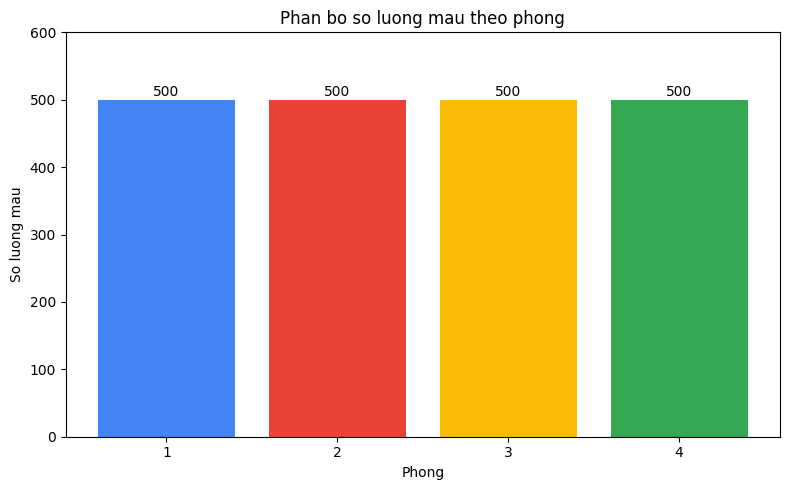


Tong so mau: 2000
Du lieu can bang: True


In [8]:

# PHAN 1C - PHAN BO NHAN 4 PHONG

import matplotlib.pyplot as plt

# Thong ke so mau va ty le phan tram
room_counts = df["Room"].value_counts().sort_index()
room_percent = df["Room"].value_counts(
    normalize=True
).sort_index() * 100

room_distribution = pd.DataFrame({
    "So_mau": room_counts,
    "Ty_le_%": room_percent
})

room_distribution.index.name = "Phong"

print("=== PHAN BO NHAN 4 PHONG ===")
display(room_distribution)

# Ve bieu do cot
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    room_counts.index.astype(str),
    room_counts.values,
    color=["#4285F4", "#EA4335", "#FBBC05", "#34A853"]
)

ax.set_title("Phan bo so luong mau theo phong")
ax.set_xlabel("Phong")
ax.set_ylabel("So luong mau")
ax.set_ylim(0, room_counts.max() * 1.2)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()
plt.show()

# Kiem tra tinh can bang cua du lieu
assert room_counts.sum() == 2000
assert len(room_counts) == 4

print("\nTong so mau:", room_counts.sum())
print("Du lieu can bang:", room_counts.nunique() == 1)


**Nhận xét:** Bộ dữ liệu WiFi Localization bao gồm 4 lớp tương ứng với 4 phòng, mỗi phòng có 500 mẫu quan sát, chiếm 25% tổng số dữ liệu. Phân bố nhãn đồng đều cho thấy bộ dữ liệu cân bằng về số lượng mẫu giữa các lớp, không xuất hiện hiện tượng mất cân bằng lớp xét theo tần suất nhãn.

Đặc điểm này tạo điều kiện thuận lợi cho việc đánh giá và so sánh các mô hình phân loại ở những phần tiếp theo, mặc dù mức độ khó phân biệt giữa các phòng còn phụ thuộc vào sự chồng lấn của đặc trưng tín hiệu WiFi.


### 1d. Thống kê mô tả các đặc trưng WiFi

Mục tiêu: Tính giá trị nhỏ nhất (Min), lớn nhất (Max)
và trung bình (Mean) của 7 đặc trưng WiFi để
khám phá phạm vi và đặc điểm phân bố cường độ tín hiệu.


In [9]:

# PHAN 1D - THONG KE MIN, MAX, MEAN

wifi_cols = [f"WiFi_{i}" for i in range(1, 8)]

# Tinh cac chi so thong ke
statistics = df[wifi_cols].agg(
    ["min", "max", "mean"]
).T

statistics.columns = ["Min", "Max", "Mean"]
statistics.index.name = "Dac_trung"

print("=== THONG KE MO TA 7 DAC TRUNG WIFI ===")
display(statistics.round(2))

# Kiem tra tinh hop le
assert statistics.shape == (7, 3)
assert (statistics["Min"] <= statistics["Mean"]).all()
assert (statistics["Mean"] <= statistics["Max"]).all()

print("\nTHONG KE THANH CONG!")


=== THONG KE MO TA 7 DAC TRUNG WIFI ===


,Min,Max,Mean
Dac_trung,,,
WiFi_1,-74.0,-10.0,-52.33
WiFi_2,-74.0,-45.0,-55.62
WiFi_3,-73.0,-40.0,-54.96
WiFi_4,-77.0,-11.0,-53.57
WiFi_5,-89.0,-36.0,-62.64
WiFi_6,-97.0,-61.0,-80.98
WiFi_7,-98.0,-63.0,-81.73



THONG KE THANH CONG!


**Nhận xét:** Kết quả thống kê mô tả cho thấy cường độ tín hiệu RSSI của 7 đặc trưng WiFi có sự khác biệt đáng kể về giá trị trung bình và phạm vi biến thiên.

Trong đó, WiFi_1 có cường độ tín hiệu trung bình cao nhất (-52.33 dBm), còn WiFi_7 có cường độ trung bình thấp nhất (-81.73 dBm). Do RSSI được biểu diễn bằng đơn vị dBm với các giá trị âm, giá trị càng gần 0 thường tương ứng với tín hiệu nhận được càng mạnh.

WiFi_4 có khoảng biến thiên lớn nhất (66 dB), cho thấy tín hiệu tại điểm phát này thay đổi trên phạm vi rộng giữa các mẫu quan sát.

Sự khác biệt về đặc điểm phân bố tín hiệu giữa các thuộc tính là cơ sở để xem xét chuẩn hóa dữ liệu trước khi áp dụng những phương pháp phụ thuộc vào thang đo và phương sai, chẳng hạn như PCA, KNN và SVM.


### 1e. Kiểm tra dữ liệu thiếu và trùng lặp

Mục tiêu: Xác định số lượng giá trị thiếu (Missing Values)
và các bản ghi trùng lặp (Duplicates) để đánh giá
chất lượng dữ liệu trước khi xây dựng mô hình.


In [10]:

# PHAN 1E - KIEM TRA MISSING VALUES VA DUPLICATES

print("=== 1. KIEM TRA GIA TRI THIEU ===")

missing_per_column = df.isnull().sum()

display(pd.DataFrame({
    "So_gia_tri_thieu": missing_per_column,
    "Ty_le_%": (missing_per_column / len(df) * 100).round(2)
}))

total_missing = df.isnull().sum().sum()

print("Tong so gia tri thieu:", total_missing)

print("\n=== 2. KIEM TRA BAN GHI TRUNG LAP ===")

duplicate_count = df.duplicated().sum()
duplicate_rate = duplicate_count / len(df) * 100

print("So ban ghi trung lap:", duplicate_count)
print("Ty le trung lap (%):", round(duplicate_rate, 2))

print("\n=== 3. KIEM TRA KICH THUOC DU LIEU ===")
print("So mau ban dau:", len(df))
print("So mau neu loai bo trung lap:",
      len(df.drop_duplicates()))

# Khong tu dong xoa duplicate
# Vi du lieu WiFi co the co cac phep do trung nhau hop le

assert df.shape == (2000, 8)

print("\nHOAN THANH KIEM TRA CHAT LUONG DU LIEU!")


=== 1. KIEM TRA GIA TRI THIEU ===


,So_gia_tri_thieu,Ty_le_%
WiFi_1,0,0.0
WiFi_2,0,0.0
WiFi_3,0,0.0
WiFi_4,0,0.0
WiFi_5,0,0.0
WiFi_6,0,0.0
WiFi_7,0,0.0
Room,0,0.0


Tong so gia tri thieu: 0

=== 2. KIEM TRA BAN GHI TRUNG LAP ===
So ban ghi trung lap: 0
Ty le trung lap (%): 0.0

=== 3. KIEM TRA KICH THUOC DU LIEU ===
So mau ban dau: 2000
So mau neu loai bo trung lap: 2000

HOAN THANH KIEM TRA CHAT LUONG DU LIEU!


**Nhận xét:** Kết quả kiểm tra chất lượng dữ liệu cho thấy bộ dữ liệu WiFi Localization không chứa giá trị thiếu ở bất kỳ thuộc tính nào. Đồng thời, không phát hiện bản ghi trùng lặp hoàn toàn trong tổng số 2.000 mẫu quan sát.

Do đó, không cần thực hiện các thao tác điền giá trị thiếu hoặc loại bỏ bản ghi trùng lặp. Toàn bộ 2.000 mẫu được giữ nguyên để bảo toàn dữ liệu phục vụ các bước phân tích và xây dựng mô hình tiếp theo.


### 1f. Phát hiện giá trị ngoại lai bằng Boxplot

Mục tiêu: Trực quan hóa phân bố RSSI của 7 đặc trưng
WiFi, xác định các giá trị ngoại lai bằng phương pháp
Interquartile Range (IQR) và đánh giá ảnh hưởng
của chúng đối với dữ liệu.


=== THONG KE GIA TRI NGOAI LAI ===


,Q1,Q3,IQR,Can_duoi,Can_tren,So_gia_tri_ngoai_lai
WiFi_1,-61.0,-46.0,15.0,-83.5,-23.5,59
WiFi_2,-58.0,-53.0,5.0,-65.5,-45.5,12
WiFi_3,-58.0,-51.0,7.0,-68.5,-40.5,9
WiFi_4,-63.0,-46.0,17.0,-88.5,-20.5,41
WiFi_5,-69.0,-56.0,13.0,-88.5,-36.5,2
WiFi_6,-86.0,-77.0,9.0,-99.5,-63.5,3
WiFi_7,-87.0,-78.0,9.0,-100.5,-64.5,14


Tong luot gia tri ngoai lai: 140
So mau chua it nhat mot ngoai lai: 105
Ty le mau co ngoai lai (%): 5.25


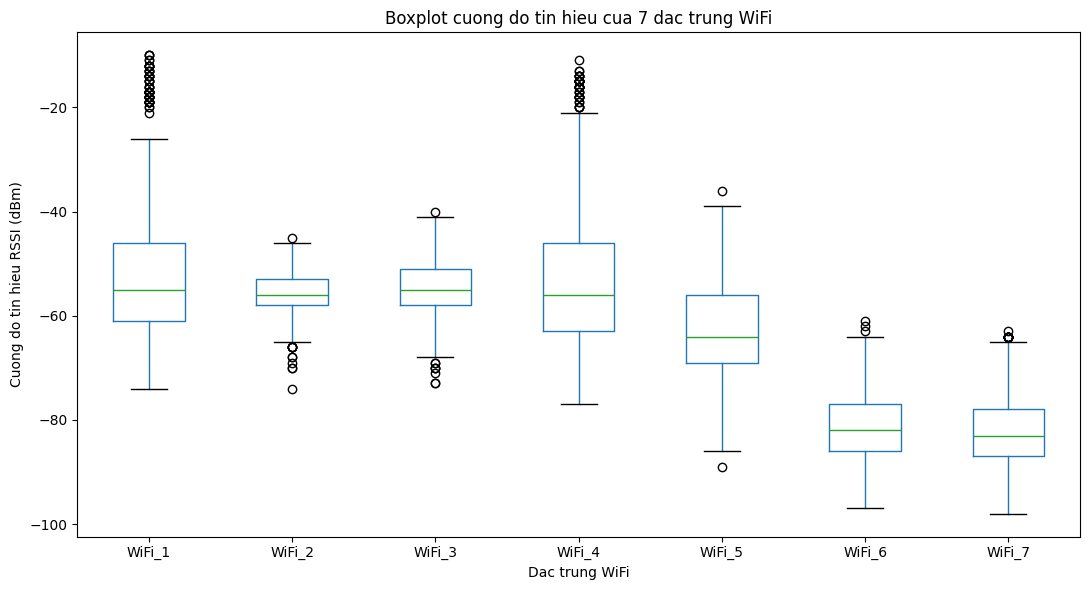


HOAN THANH PHAN TICH NGOAI LAI!


In [11]:

# PHAN 1F - PHAT HIEN NGOAI LAI BANG IQR VA BOXPLOT

import matplotlib.pyplot as plt
import pandas as pd

wifi_cols = [f"WiFi_{i}" for i in range(1, 8)]

# Tinh Q1, Q3 va IQR cho tung dac trung
Q1 = df[wifi_cols].quantile(0.25)
Q3 = df[wifi_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Kiem tra gia tri ngoai lai theo tung cot
outlier_mask = (
    (df[wifi_cols] < lower_bound) |
    (df[wifi_cols] > upper_bound)
)

outlier_counts = outlier_mask.sum()

# Dem so dong co it nhat mot gia tri ngoai lai
outlier_rows = outlier_mask.any(axis=1).sum()

outlier_summary = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Can_duoi": lower_bound,
    "Can_tren": upper_bound,
    "So_gia_tri_ngoai_lai": outlier_counts
})

print("=== THONG KE GIA TRI NGOAI LAI ===")
display(outlier_summary.round(2))

print("Tong luot gia tri ngoai lai:", outlier_counts.sum())
print("So mau chua it nhat mot ngoai lai:", outlier_rows)
print("Ty le mau co ngoai lai (%):",
      round(outlier_rows / len(df) * 100, 2))

# Ve Boxplot
fig, ax = plt.subplots(figsize=(11, 6))

df[wifi_cols].boxplot(
    ax=ax,
    grid=False,
    showfliers=True
)

ax.set_title("Boxplot cuong do tin hieu cua 7 dac trung WiFi")
ax.set_xlabel("Dac trung WiFi")
ax.set_ylabel("Cuong do tin hieu RSSI (dBm)")

plt.tight_layout()
plt.show()

print("\nHOAN THANH PHAN TICH NGOAI LAI!")


**Nhận xét:** Kết quả phân tích bằng phương pháp khoảng tứ phân vị (IQR) với hệ số 1,5 cho thấy bộ dữ liệu WiFi Localization có 105 mẫu chứa ít nhất một giá trị ngoại lai, chiếm 5,25% tổng số 2.000 mẫu quan sát.

Khi xét riêng từng đặc trưng, tổng số lượt giá trị ngoại lai là 140, trong đó WiFi_1 có nhiều nhất (59 lượt), tiếp theo là WiFi_4 (41 lượt). Sự khác biệt giữa 140 lượt ngoại lai và 105 mẫu chứa ngoại lai xuất phát từ việc một mẫu có thể đồng thời có giá trị vượt ngưỡng IQR ở nhiều thuộc tính.

Các điểm ngoại lai được xác định theo tiêu chí thống kê, không đồng nghĩa với dữ liệu sai hoặc nhiễu cần loại bỏ. Trong bài toán định vị bằng tín hiệu WiFi, cường độ RSSI có thể biến động do khoảng cách, vật cản, phản xạ sóng và điều kiện môi trường.

Do đó, nhóm quyết định giữ nguyên 105 mẫu chứa ngoại lai, không tự động loại bỏ để tránh làm mất thông tin có thể hữu ích cho việc nhận diện vị trí. Bộ dữ liệu tiếp tục được bảo toàn đủ 2.000 mẫu cho các bước chuẩn hóa, giảm chiều và xây dựng mô hình.